# Лабораторная работа № 4
## Вариант 7

# Задание 1. Задача Коши

y'''-y''+3t\sin(y')+3y=0
с начальными условиями
y(0)=0, y'(0)=-1,y''(0)=-1.

Решаем уравнение на отрезке [0,2] с помощью `scipy.integrate.solve_ivp`.

## Преобразование к системе первого порядка

Введём новые функции:
y_1=y, y_2=y',y_3=y''.
Тогда
y_1'=y_2,y_2'=y_3.
Из исходного уравнения получаем
y'''=y''-3t\sin(y')-3y,
следовательно,
y_3'=y_3-3t\sin(y_2)-3y_1.

Начальные условия для системы:
y_1(0)=0, y_2(0)=-1, y_3(0)=-1.

Решение успешно вычислено.
y(2) ≈ 0.12073544
y'(2) ≈ 6.02190947
y''(2) ≈ 13.58266538


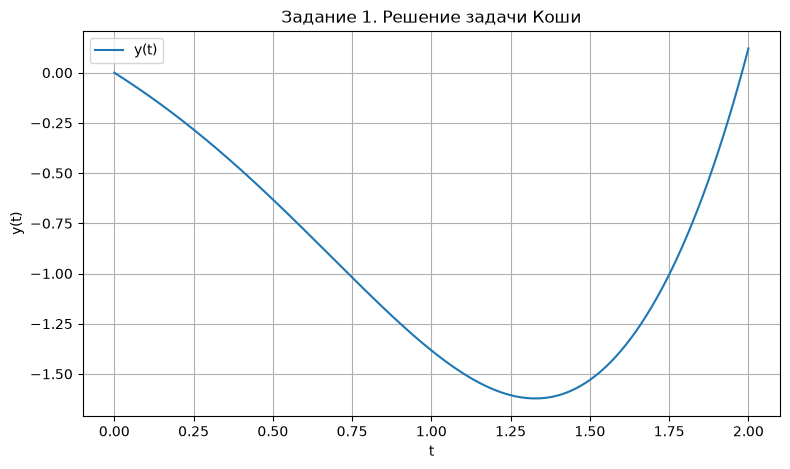

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def system(t, Y):
    y1, y2, y3 = Y
    return [
        y2,
        y3,
        y3 - 3 * t * np.sin(y2) - 3 * y1
    ]

t_span = (0, 2)
t_values = np.linspace(0, 2, 500)
Y0 = [0, -1, -1]

solution = solve_ivp(
    system,
    t_span,
    Y0,
    t_eval=t_values,
    method="RK45",
    rtol=1e-8,
    atol=1e-10
)

if not solution.success:
    raise RuntimeError(solution.message)

y = solution.y[0]
y_prime = solution.y[1]
y_double_prime = solution.y[2]

print("Решение успешно вычислено.")
print(f"y(2) ≈ {y[-1]:.8f}")
print(f"y'(2) ≈ {y_prime[-1]:.8f}")
print(f"y''(2) ≈ {y_double_prime[-1]:.8f}")

plt.figure(figsize=(9, 5))
plt.plot(solution.t, y, label="y(t)")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.title("Задание 1. Решение задачи Коши")
plt.grid(True)
plt.legend()
plt.show()

# Задание 2. Краевая задача

Задано:
u''+\frac{1}{x}u'=9x+4, 1<x<2,
с краевыми условиями
u'(1)+u(1)=7, 2u(2)-u'(2)=8.
## Преобразование к системе первого порядка

Положим

u_1=u, u_2=u'.
Тогда

u_1'=u_2.
Из уравнения

u''+\frac{1}{x}u'=9x+4
получаем

u''=9x+4-\frac{u'}{x},
поэтому система имеет вид

u_1'=u_2,
u_2'=9x+4-\frac{u_2}{x}.

Краевые условия в новых обозначениях:

u_2(1)+u_1(1)=7,

2u_1(2)-u_2(2)=8.

Решение краевой задачи успешно вычислено.
u(1) ≈ 2.00000000
u'(1) ≈ 5.00000000
u(2) ≈ 12.00000000
u'(2) ≈ 16.00000000

Проверка краевых условий:
u'(1) + u(1) ≈ 7.00000000 (должно быть 7)
2u(2) - u'(2) ≈ 8.00000000 (должно быть 8)


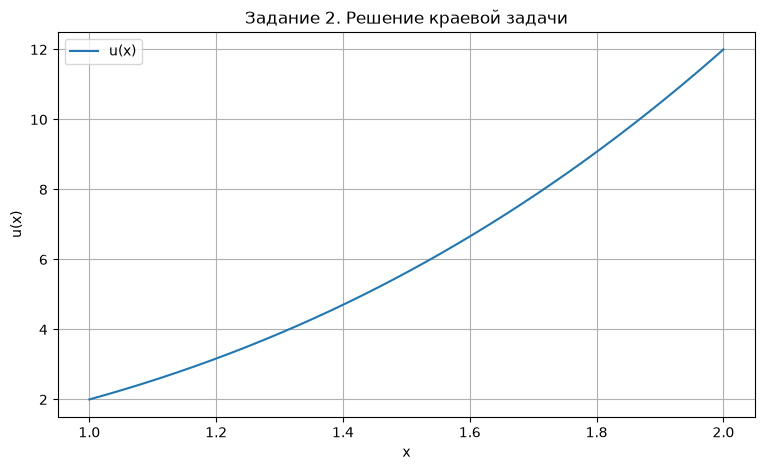

In [2]:
from scipy.integrate import solve_bvp

def ode_system(x, U):
    u = U[0]
    up = U[1]
    return np.vstack((
        up,
        9 * x + 4 - up / x
    ))

def boundary_conditions(U_left, U_right):
    # U_left соответствует x=1, U_right — x=2
    return np.array([
        U_left[1] + U_left[0] - 7,
        2 * U_right[0] - U_right[1] - 8
    ])

x_mesh = np.linspace(1, 2, 100)

# Начальное приближение для u(x) и u'(x)
U_guess = np.zeros((2, x_mesh.size))

bvp_solution = solve_bvp(
    ode_system,
    boundary_conditions,
    x_mesh,
    U_guess,
    tol=1e-8,
    max_nodes=10000
)

if not bvp_solution.success:
    raise RuntimeError(bvp_solution.message)

x_plot = np.linspace(1, 2, 400)
U_plot = bvp_solution.sol(x_plot)
u = U_plot[0]
u_prime = U_plot[1]

print("Решение краевой задачи успешно вычислено.")
print(f"u(1) ≈ {bvp_solution.sol(1)[0]:.8f}")
print(f"u'(1) ≈ {bvp_solution.sol(1)[1]:.8f}")
print(f"u(2) ≈ {bvp_solution.sol(2)[0]:.8f}")
print(f"u'(2) ≈ {bvp_solution.sol(2)[1]:.8f}")

print("\nПроверка краевых условий:")
print(f"u'(1) + u(1) ≈ {bvp_solution.sol(1)[1] + bvp_solution.sol(1)[0]:.8f} (должно быть 7)")
print(f"2u(2) - u'(2) ≈ {2*bvp_solution.sol(2)[0] - bvp_solution.sol(2)[1]:.8f} (должно быть 8)")

plt.figure(figsize=(9, 5))
plt.plot(x_plot, u, label="u(x)")
plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("Задание 2. Решение краевой задачи")
plt.grid(True)
plt.legend()
plt.show()

# Вывод

1. Задача Коши третьего порядка преобразована к системе трёх уравнений первого порядка и решена численно методом `solve_ivp` на отрезке [0,2].
2. Краевая задача второго порядка преобразована к системе двух уравнений первого порядка и решена методом `solve_bvp` на отрезке [1,2].
